In [11]:
# Core data structures and numerical array processing frameworks
import pandas as pd
import numpy as np

# Data presentation, plotting engines, and visualization modules
import matplotlib.pyplot as plt
import seaborn as sns

# SciKit-Learn machine learning validation tools and cross-validation matrix tools
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Classification report metrics, ROC, and Precision-Recall tracking graphs
from sklearn.metrics import classification_report, roc_auc_score, roc_curve

# Advanced balancing framework targeting highly imbalanced vector categories
from imblearn.over_sampling import SMOTE

print("Pipeline packages successfully compiled and environment configured.")


Pipeline packages successfully compiled and environment configured.


### Why Standard Accuracy is a Misleading Metric
In fraud detection, datasets are heavily skewed. For instance, if a dataset contains 99.8% legitimate transactions and 0.2% fraudulent ones, a broken model that blindly classifies *every single transaction as legitimate* will achieve a **99.8% accuracy score**.

While mathematically high, this model is completely useless because it catches 0% of actual fraud. Accuracy treats all classification errors equally, whereas missing a multi-thousand-dollar fraud case (False Negative) is significantly more damaging to a business than flagging a legitimate user for verification (False Positive). Therefore, optimization must target metrics that isolate minority class identification performance.

Dataset Loaded. Raw Structure Dimensions: (4424489, 11)

📊 Class Distribution Metrics:
Legitimate Transactions (0): 4420861 (99.918%)
Fraudulent Transactions (1): 3627 (0.082%)



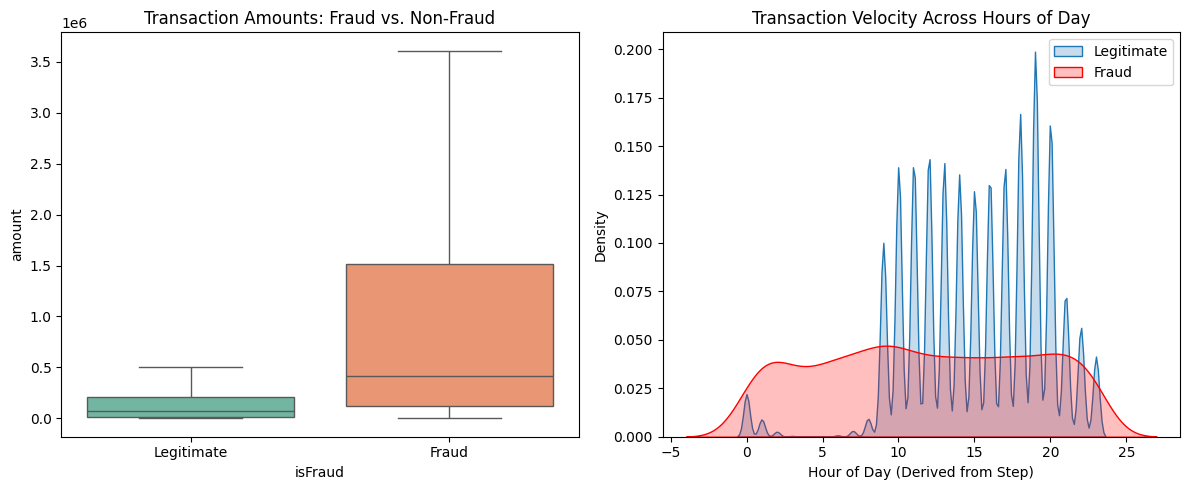

In [12]:

# Read data files while cleaning up any potential padding inside the source file columns
df = pd.read_csv("Synthetic_Financial_datasets_log.csv", skipinitialspace=True)
df.columns = df.columns.str.replace('"', '').str.strip()
print(f"Dataset Loaded. Raw Structure Dimensions: {df.shape}")

# Calculate explicit matrix distribution characteristics for minority and majority classes
fraud_count = df['isFraud'].value_counts()
fraud_pct = df['isFraud'].value_counts(normalize=True) * 100
print(f"\n📊 Class Distribution Metrics:")
print(f"Legitimate Transactions (0): {fraud_count[0]} ({fraud_pct[0]:.3f}%)")
print(f"Fraudulent Transactions (1): {fraud_count[1]} ({fraud_pct[1]:.3f}%)\n")

# PaySim uses 'step' instead of a datetime 'timestamp' string.
# Each step represents 1 hour, so we map it directly to a 24-hour cycle.
df['Hour'] = df['step'] % 24

# --- Visual Inspection Block ---
plt.figure(figsize=(12, 5))

# Plot 1: Compare purchase costs across categories
plt.subplot(1, 2, 1)
sns.boxplot(x='isFraud', y='amount', hue='isFraud', data=df, showfliers=False, palette="Set2", legend=False)
plt.title("Transaction Amounts: Fraud vs. Non-Fraud")
plt.xticks([0, 1], ['Legitimate', 'Fraud'])

# Plot 2: Compare transaction times using the step-derived Hour column
plt.subplot(1, 2, 2)
sns.kdeplot(df[df['isFraud'] == 0]['Hour'], label='Legitimate', fill=True)
sns.kdeplot(df[df['isFraud'] == 1]['Hour'], label='Fraud', fill=True, color='red')
plt.title("Transaction Velocity Across Hours of Day")
plt.xlabel("Hour of Day (Derived from Step)")
plt.legend()

plt.tight_layout()
plt.show()


In [ ]:
# 1. Target and Tracking ID Isolation
y = df['isFraud']

# PaySim has no 'transaction_id' column, so we use the index as our parallel tracker
tx_ids = pd.Series(df.index, name='transaction_id')

# PaySim Specific Exclusions: drop target, our derived hour, and non-numeric strings
exclude_cols = ['isFraud', 'Hour', 'type', 'nameOrig', 'nameDest']

# Automatically isolate numeric columns to create clean structural training arrays
num_cols = [
    col for col in df.columns
    if pd.api.types.is_numeric_dtype(df[col]) and col not in exclude_cols
]
X = df[num_cols]
print("Selected PaySim numeric features for training:", X.columns.tolist())

# 2. Stratified Cross-Validation Splitting
X_train, X_test, y_train, y_test, ids_train, ids_test = train_test_split(
    X, y, tx_ids, test_size=0.2, stratify=y, random_state=42
)
print(f"\nRaw Train Set Layout: Legitimate = {np.bincount(y_train)[0]}, Fraud = {np.bincount(y_train)[1]}")

# 3. Memory-Safe Strategic Downsampling
# Isolate indices of both classes within the training split
legit_indices = y_train[y_train == 0].index
fraud_indices = y_train[y_train == 1].index

# Downsample legitimate rows to 100,000 to drastically save RAM while keeping all real fraud
np.random.seed(42)
sampled_legit_indices = np.random.choice(legit_indices, size=100000, replace=False)

# Combine downsampled indices
safe_train_indices = np.concatenate([sampled_legit_indices, fraud_indices])

# Slice the training data using our memory-safe index layout
X_train_safe = X_train.loc[safe_train_indices]
y_train_safe = y_train.loc[safe_train_indices]
print(f"Downsampled Train Layout (RAM Protected): Legitimate = {np.bincount(y_train_safe)[0]}, Fraud = {np.bincount(y_train_safe)[1]}")

# 4. Apply SMOTE safely to the downsampled training subset
# This runs perfectly on phone setups/Colab without throwing out-of-memory errors!
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train_safe, y_train_safe)
print(f"Final Balanced Training Class Layout: {np.bincount(y_train_res)}")



Selected PaySim numeric features for training: ['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'isFlaggedFraud']

Raw Train Set Layout: Legitimate = 654414, Fraud = 374
Downsampled Train Layout (RAM Protected): Legitimate = 100000, Fraud = 374
Final Balanced Training Class Layout: [100000 100000]


In [ ]:
# Define model training parameters and hyperparameter search grids
models_config = {
    'LogisticRegression': {
        'model': LogisticRegression(max_iter=1000, random_state=42),
        'params': {'C': [0.1, 1, 10]}
    },
    'RandomForest': {
        'model': RandomForestClassifier(random_state=42),
        'params': {'n_estimators': [100, 150], 'max_depth': [5, 10, None]}
    }
}

best_models = {}

# Iterate over each pipeline setup to run optimization cross-validation steps
for name, config in models_config.items():
    print(f"\nTuning hyperparameter permutations for: {name}...")

    # Configure cross-validation grids using macro F1 scoring to protect the minority class
    grid = GridSearchCV(
        estimator=config['model'],
        param_grid=config['params'],
        cv=3,
        scoring='f1_macro',
        n_jobs=-1
    )

    # Train grids exclusively on your freshly balanced synthetic training samples
    grid.fit(X_train_res, y_train_res)
    print(f"Optimal Settings Found: {grid.best_params_}")

    # Save optimized estimators directly into the baseline model index dictionary
    best_models[name] = grid.best_estimator_



Tuning hyperparameter permutations for: LogisticRegression...
Optimal Settings Found: {'C': 0.1}

Tuning hyperparameter permutations for: RandomForest...
Optimal Settings Found: {'max_depth': None, 'n_estimators': 100}


In [ ]:
plt.figure(figsize=(14, 5))

# Evaluate each model on the clean, un-oversampled validation test dataset
for idx, (name, model) in enumerate(best_models.items()):
    # Calculate probabilities and predict binary values
    y_pred_prob = model.predict_proba(X_test)[:, 1]
    y_pred = model.predict(X_test)

    print(f"\n" + "="*50 + f"\n--- {name} Classification Performance Data ---\n" + "="*50)
    print(classification_report(y_test, y_pred, target_names=['Legitimate', 'Fraud']))
    print(f"Area Under ROC Curve (AUC-ROC Metrics): {roc_auc_score(y_test, y_pred_prob):.4f}")

    # Extract True Positive and False Positive rates to plot validation lines
    fpr, tpr, _ = roc_curve(y_test, y_pred_prob)

    plt.subplot(1, 2, 1)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc_score(y_test, y_pred_prob):.2f})')

# Plot a baseline reference line representing random predictions
plt.subplot(1, 2, 1)
plt.plot([0, 1], [0, 1], 'k--', label='Random Guessing Profile')
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate / Recall (TPR)')
plt.title('Receiver Operating Characteristic (ROC) Validation Curve')
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:
# Extract feature importance values from the trained Random Forest model
rf_instance = best_models['RandomForest']
importances = rf_instance.feature_importances_

# Sort and rank features by how much predictive value they add to the model
sorted_indices = np.argsort(importances)[::-1]

# Plot feature importance weights
plt.figure(figsize=(10, 5))
sns.barplot(
    x=importances[sorted_indices],
    y=np.array(X.columns)[sorted_indices],
    hue=np.array(X.columns)[sorted_indices],
    palette="muted",
    legend=False
)
plt.title("Feature Importance Weights Dictating Fraud Profiles (Information Gain)")
plt.xlabel("Relative Importance Weight Score")
plt.ylabel("Dataset Columns")
plt.tight_layout()
plt.show()


### 1. The Metric Priority Debate: Recall vs. Precision
For transaction tracking, **Recall matters most**.

* **Recall** measures what percentage of actual fraud cases the pipeline successfully intercepted. A high recall means fewer fraudulent transactions slip past the system into customer bank statements.
* **Precision** measures what percentage of flagged transaction alerts are genuinely fraudulent. Low precision means a higher number of "False Positives" (legitimate users getting their card temporarily declined).

**The Decision:** Financial institutions prioritize catching criminals over minimal user inconvenience. It is significantly safer to deal with the operational customer-service cost of reviewing false alarms (Low Precision) than it is to suffer the legal, financial, and reputational fallout of failing to detect massive criminal theft runs (Low Recall).

### 2. Pipeline Infrastructure Scalability (1 Million Transactions/Hour)
Processing **1,000,000 records per hour** (~278 transactions per second) introduces immediate latency constraints that cannot be served by a basic offline Jupyter notebook script. To scale this infrastructure:

* **Separation of Concerns:** Split the pipeline into a distributed offline **Batch Training Loop** (e.g., retraining the Random Forest using Apache Spark or Ray on historical logs once a week) and an online **Real-Time Inference API**.
* **Model Serialization & Microservices:** Export the optimized models via `joblib` or `ONNX` and package them into lightweight asynchronous container microservices (FastAPI / Docker) deployed behind a load balancer.
* **In-Memory Streaming Buffers:** Implement streaming event buses like **Apache Kafka** or AWS Kinesis to buffer incoming transaction data streams instantly. Pair these with an in-memory data cache engine like **Redis** to retrieve historical features (e.g., matching a customer's rolling 24-hour balance change velocity) within single-digit millisecond windows before running model predictions.